In [4]:
import h5py
import numpy as np

filename = "single_parameter_u_scan_small_0005.mat"

with h5py.File(filename, "r") as f:
    print(list(f.keys()))

['#refs#', 'f_values', 'u_all']


In [5]:
with h5py.File(filename, "r") as f:
    f_values = np.array(f["f_values"])
    u_all = np.array(f["u_all"]).squeeze()

print(f_values.shape)
print(u_all.shape)

(101, 1)
(101,)


In [6]:
f_values

array([[ 0.  ],
       [-0.01],
       [-0.02],
       [-0.03],
       [-0.04],
       [-0.05],
       [-0.06],
       [-0.07],
       [-0.08],
       [-0.09],
       [-0.1 ],
       [-0.11],
       [-0.12],
       [-0.13],
       [-0.14],
       [-0.15],
       [-0.16],
       [-0.17],
       [-0.18],
       [-0.19],
       [-0.2 ],
       [-0.21],
       [-0.22],
       [-0.23],
       [-0.24],
       [-0.25],
       [-0.26],
       [-0.27],
       [-0.28],
       [-0.29],
       [-0.3 ],
       [-0.31],
       [-0.32],
       [-0.33],
       [-0.34],
       [-0.35],
       [-0.36],
       [-0.37],
       [-0.38],
       [-0.39],
       [-0.4 ],
       [-0.41],
       [-0.42],
       [-0.43],
       [-0.44],
       [-0.45],
       [-0.46],
       [-0.47],
       [-0.48],
       [-0.49],
       [-0.5 ],
       [-0.51],
       [-0.52],
       [-0.53],
       [-0.54],
       [-0.55],
       [-0.56],
       [-0.57],
       [-0.58],
       [-0.59],
       [-0.6 ],
       [-0.61],
       [

In [12]:
import h5py
import numpy as np

def read_mat73_obj(f, obj):

    # dataset
    if isinstance(obj, h5py.Dataset):

        data = obj[()]

        # MATLAB cell：里面存的是 reference
        if data.dtype == h5py.ref_dtype or data.dtype.kind == "O":

            result = []

            for ref in data.flatten():

                if not ref:
                    result.append(None)
                    continue

                sub_obj = f[ref]

                result.append(
                    read_mat73_obj(f, sub_obj)
                )

            return result

        # MATLAB complex
        if data.dtype.names is not None:
            if "real" in data.dtype.names and "imag" in data.dtype.names:
                return data["real"] + 1j * data["imag"]

        return np.array(data)

    # group
    elif isinstance(obj, h5py.Group):

        return {
            key: read_mat73_obj(f, obj[key])
            for key in obj.keys()
        }

In [29]:
filename = "single_parameter_u_scan_small_0005.mat"

with h5py.File(filename, "r") as f:

    data = read_mat73_obj(f, f["u_all"])


filename = "single_parameter_u_scan_small_002.mat"

with h5py.File(filename, "r") as f:

    data1 = read_mat73_obj(f, f["u_all"])


filename = "single_parameter_u_scan_small_004.mat"

with h5py.File(filename, "r") as f:

    data2 = read_mat73_obj(f, f["u_all"])

In [30]:
data[0][2]

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],

In [22]:
import matplotlib as plt

In [31]:
y = []
y1 = []
y2 = []
for i in range(len(data)):
    y.append(np.mean(data[i][2]))
    y1.append(np.mean(data1[i][2]))
    y2.append(np.mean(data2[i][2]))

In [32]:
filename = "single_parameter_u_scan_0005.mat"

with h5py.File(filename, "r") as f:

    data = read_mat73_obj(f, f["u_all"])


filename = "single_parameter_u_scan_002.mat"

with h5py.File(filename, "r") as f:

    data1 = read_mat73_obj(f, f["u_all"])


filename = "single_parameter_u_scan_004.mat"

with h5py.File(filename, "r") as f:

    data2 = read_mat73_obj(f, f["u_all"])

In [33]:
z = []
z1 = []
z2 = []
for i in range(len(data)):
    z.append(np.mean(data[i][2]))
    z1.append(np.mean(data1[i][2]))
    z2.append(np.mean(data2[i][2]))

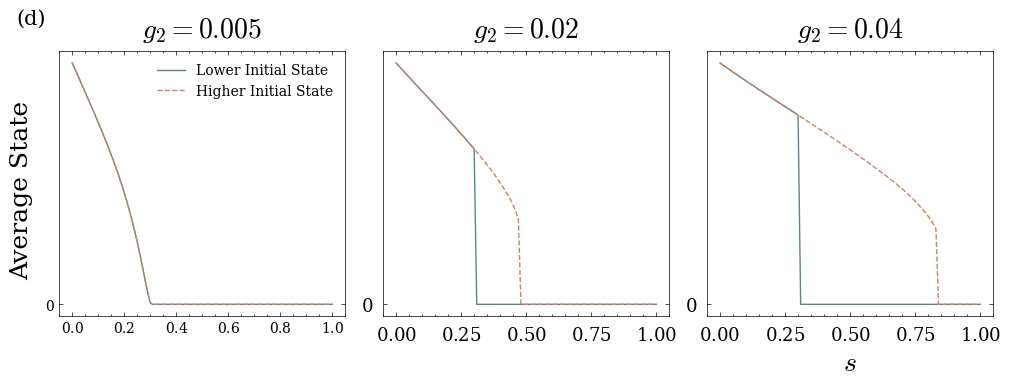

In [122]:
import matplotlib.pyplot as plt
import scienceplots

from matplotlib.ticker import MaxNLocator, FuncFormatter
with plt.style.context(['science', 'no-latex']): 
    fig, ax = plt.subplots(
        1, 3,
        figsize=(10, 4),
        sharex=False
    )
    # fig.subplots_adjust(hspace=-1)
    # 第一组
    ax[0].plot(-f_values, y, '-', label='Lower Initial State', color = '#58878A')
    ax[0].plot(-f_values, z, '--', label='Higher Initial State', color = '#CC8264')
    ax[0].legend(frameon=False,fontsize=10, loc='upper right')
    ax[0].tick_params(axis='both', labelsize=10, pad=3)
    ax[0].set_title(r'$g_2 = 0.005$',fontsize=20, pad=10)
    ax[0].text(-0.15,1.1,'(d)',fontsize=15,transform=ax[0].transAxes)
    ax[0].set_yticks([0])
    
    # 第二组
    ax[1].plot(-f_values, y1, '-', label='Lower Initial State', color = '#58878A')
    ax[1].plot(-f_values, z1, '--', label='Higher Initial State', color = '#CC8264')
    # ax[1].legend(frameon=False,fontsize=9, loc='upper left')
    ax[1].set_title(r'$g_2 = 0.02$',fontsize=20, pad=10)
    ax[1].tick_params(axis='both', labelsize=13, pad=7)
    ax[1].set_yticks([0])
    
    # 第三组
    ax[2].plot(-f_values, y2, '-', label='Lower Initial State', color = '#58878A')
    ax[2].plot(-f_values, z2, '--', label='Higher Initial State', color = '#CC8264')
    # ax[2].legend(frameon=False,fontsize=9, loc='upper left')
    ax[2].set_title(r'$g_2 = 0.04$',fontsize=20, pad=10)
    ax[2].tick_params(axis='both', labelsize=13, pad=7)
    ax[2].set_yticks([0])
    
    ax[2].set_xlabel(r'$s$',fontsize=20)
    # ax[2].set_ylabel('Average\n State',fontsize=14)

    
    
    plt.tight_layout(h_pad=0.3)
    fig.supylabel('Average State',fontsize=18,x=0.0)
# plt.savefig("SIS_hysteresis.pdf", format='pdf', dpi=300)
plt.show()

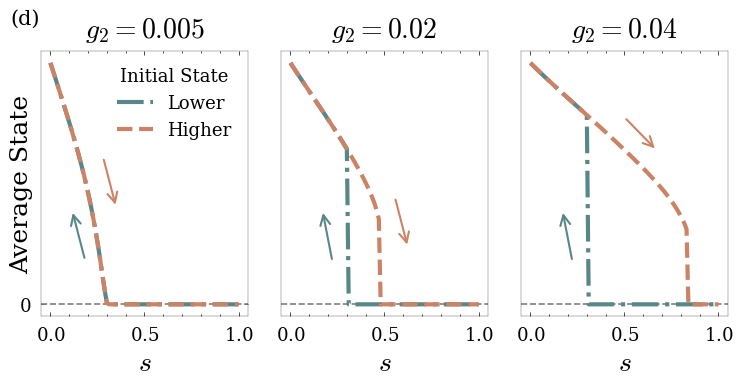

In [169]:
import matplotlib.pyplot as plt
import scienceplots
from matplotlib.patches import FancyArrowPatch

from matplotlib.ticker import MaxNLocator, FuncFormatter
with plt.style.context(['science', 'no-latex']): 
    fig, ax = plt.subplots(
        1, 3,
        figsize=(7.5, 4),
        sharex=False
    )
    bwith = 0.2

    for a in ax:
        a.spines['bottom'].set_linewidth(bwith)
        a.spines['left'].set_linewidth(bwith)
        a.spines['top'].set_linewidth(bwith)
        a.spines['right'].set_linewidth(bwith)
        a.axhline(0, color='0.5', linestyle='--', linewidth=1.2)
    
    # fig.subplots_adjust(hspace=-1)
    # 第一组
    ax[0].plot(-f_values, y, '-.',linewidth=3,  label='Lower', color = '#58878A')
    ax[0].plot(-f_values, z, '--',linewidth=3,  label='Higher', color = '#CC8264')
    # ax[0].legend(frameon=False,fontsize=13, loc='upper right')
    leg = ax[0].legend(title="Initial State",frameon=False,fontsize=13,title_fontsize=9)
    leg.get_title().set_fontsize(13)
    ax[0].tick_params(axis='both', labelsize=13, pad=7)
    ax[0].set_title(r'$g_2 = 0.005$',fontsize=20, pad=10)
    ax[0].text(-0.15,1.1,'(d)',fontsize=15,transform=ax[0].transAxes)
    ax[0].set_yticks([0])
    ax[0].set_xlabel(r'$s$',fontsize=20)
    ax[0].set_ylabel('Average State',fontsize=18,labelpad=-10)

    k = -3             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.3, 0.6   # 起点
    arrow = FancyArrowPatch(
        (xx, yy), (xx + dx, yy + dy),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#CC8264',
        transform=ax[0].transAxes
    )
    ax[0].add_patch(arrow)

    xx, yy = 0.15, 0.4   # 起点
    arrow = FancyArrowPatch(
        (xx+dx, yy+dy), (xx , yy ),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#58878A',
        transform=ax[0].transAxes
    )
    ax[0].add_patch(arrow)
    
    
    # 第二组
    ax[1].plot(-f_values, y1, '-.',linewidth=3,  label='Lower Initial State', color = '#58878A')
    ax[1].plot(-f_values, z1, '--',linewidth=3,  label='Higher Initial State', color = '#CC8264')
    # ax[1].legend(frameon=False,fontsize=9, loc='upper left')
    ax[1].set_title(r'$g_2 = 0.02$',fontsize=20, pad=10)
    ax[1].tick_params(axis='both', labelsize=13, pad=7)
    # ax[1].set_yticks([0])
    ax[1].set_yticks([])
    ax[1].set_xlabel(r'$s$',fontsize=20)

    k = -3             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.55, 0.45   # 起点
    arrow = FancyArrowPatch(
        (xx, yy), (xx + dx, yy + dy),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#CC8264',
        transform=ax[1].transAxes
    )
    ax[1].add_patch(arrow)
    
    k = -4             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.2, 0.4   # 起点
    arrow = FancyArrowPatch(
        (xx+dx, yy+dy), (xx , yy ),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#58878A',
        transform=ax[1].transAxes
    )
    ax[1].add_patch(arrow)
    
    
    # 第三组
    ax[2].plot(-f_values, y2, '-.',linewidth=3,  label='Lower Initial State', color = '#58878A')
    ax[2].plot(-f_values, z2, '--',linewidth=3,  label='Higher Initial State', color = '#CC8264')
    # ax[2].legend(frameon=False,fontsize=9, loc='upper left')
    ax[2].set_title(r'$g_2 = 0.04$',fontsize=20, pad=10)
    ax[2].tick_params(axis='both', labelsize=13, pad=7)
    # ax[2].set_yticks([0])
    ax[2].set_yticks([])
    
    ax[2].set_xlabel(r'$s$',fontsize=20)

    k = -0.8             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.5, 0.75   # 起点
    arrow = FancyArrowPatch(
        (xx, yy), (xx + dx, yy + dy),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#CC8264',
        transform=ax[2].transAxes
    )
    ax[2].add_patch(arrow)
    
    k = -4             # 斜率
    L = 0.2
    dx = L / np.sqrt(1 + k**2)
    dy = k * dx
    xx, yy = 0.2, 0.4   # 起点
    arrow = FancyArrowPatch(
        (xx+dx, yy+dy), (xx , yy ),
        arrowstyle='->',
        mutation_scale=18,
        linewidth=1.5,
        color='#58878A',
        transform=ax[2].transAxes
    )
    ax[2].add_patch(arrow)
    
    # ax[2].set_ylabel('Average\n State',fontsize=14)
    plt.tight_layout()
    fig.subplots_adjust(wspace=0.16)
    # fig.supylabel('Average State',fontsize=18,x=0.0)
plt.savefig("SIS_hysteresis.pdf", format='pdf', dpi=300)
plt.show()